In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("../reports", exist_ok=True)   # сюда сохраняем графики и отчёты

df = pd.read_csv("data/financial_sentiment.csv")
df = df.rename(columns={"Sentence": "text", "Sentiment": "sentiment"})
print(df.shape)
df.head()

(5842, 2)


,text,sentiment
0,The GeoSolutions technology will leverage Bene...,positive
1,"$ESI on lows, down $1.50 to $2.50 BK a real po...",negative
2,"For the last quarter of 2010 , Componenta 's n...",positive
3,According to the Finnish-Russian Chamber of Co...,neutral
4,The Swedish buyout firm has sold its remaining...,neutral


In [2]:
df.info()
print(df.isnull().sum())
df = df.dropna(subset=["text"])

print("дубликатов текста:", df["text"].duplicated().sum())
conflict = df.groupby("text")["sentiment"].nunique()
print("тексты с разными метками:", (conflict > 1).sum())

<class 'pandas.DataFrame'>
RangeIndex: 5842 entries, 0 to 5841
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   text       5842 non-null   str  
 1   sentiment  5842 non-null   str  
dtypes: str(2)
memory usage: 801.8 KB
text         0
sentiment    0
dtype: int64
дубликатов текста: 520
тексты с разными метками: 514


sentiment
neutral     3130
positive    1852
negative     860
Name: count, dtype: int64
sentiment
neutral     53.6
positive    31.7
negative    14.7
Name: proportion, dtype: float64


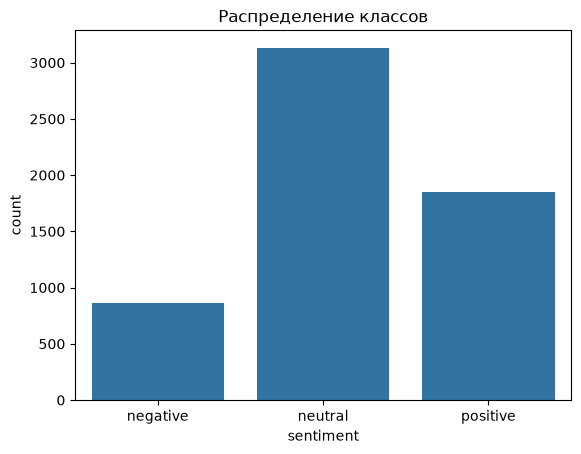

In [3]:
print(df["sentiment"].value_counts())
print((df["sentiment"].value_counts(normalize=True) * 100).round(1))

sns.countplot(data=df, x="sentiment", order=["negative", "neutral", "positive"])
plt.title("Распределение классов")
plt.savefig("../reports/sentiment_distribution.png", bbox_inches="tight")
plt.show()

       text_length   word_count
count  5842.000000  5842.000000
mean    117.022253    21.004793
std      56.420425    10.306465
min       9.000000     2.000000
25%      72.000000    13.000000
50%     107.000000    19.000000
75%     150.000000    27.000000
max     315.000000    81.000000
sentiment
negative    17.0
neutral     21.0
positive    18.0
Name: word_count, dtype: float64


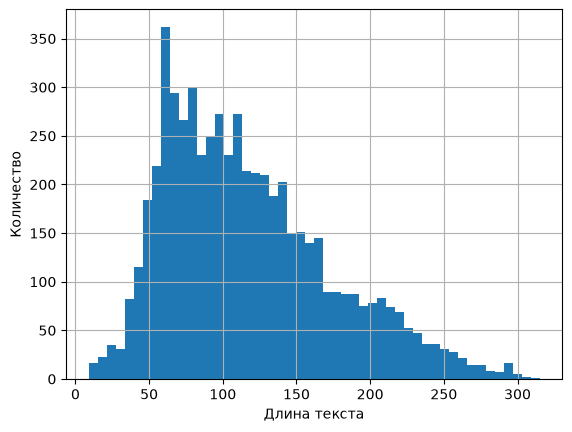

In [4]:
df["text_length"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()

print(df[["text_length", "word_count"]].describe())
print(df.groupby("sentiment")["word_count"].median())

df["text_length"].hist(bins=50)
plt.xlabel("Длина текста")
plt.ylabel("Количество")
plt.savefig("../reports/text_length_distribution.png", bbox_inches="tight")
plt.show()

In [5]:
for s in ["negative", "neutral", "positive"]:
    print(f"\n=== {s} ===")
    for t in df[df["sentiment"] == s]["text"].sample(3, random_state=42):
        print("-", t)


=== negative ===
- `` Adjustment to the fall in price level , in contrast , has been less effective .
- Hard to find new buyers of $TSLA at 250.  Shorts continue to pile in.
- Finnlines estimated in its annual general meeting that 2008 will be financially a tough year due to large investments .

=== neutral ===
- The fixed acquisition price amounts to NOK 70 ( approximately EUR 8.7 ) million and additional price NOK 15 ( EUR 1.8 ) million at maximum .
- The Finnish company previously said its operating result will be lower than the break-even posted a year earlier .
- Westpac Banking Corp - Is to issue a benchmark , 3 year FRN deal in Euros .

=== positive ===
- Sales VAT inclusive expanded by 19 percent , to 351 million euros .
- $FB Big Money Is Pouring Into Facebook From All Directions;http://stks.co/sOwG
- According to CEO Matti Karppinen , Frozen Foods posted a good result in 2010 , as it did in 2009 .


## Выводы

- задача: тональность финансовых новостей, 3 класса (negative / neutral / positive)
- размер: 5842 строки, 2 колонки, пропусков нет
- дубликатов 520, из них 514 текстов имеют РАЗНЫЕ метки - это шум разметки
  (похоже, датасет склеен из двух источников, и одно предложение размечено дважды по-разному);
  такие тексты уберём на этапе подготовки, иначе для них нет правильного ответа
- классы: neutral ...%, positive ...%, negative ...% -> дисбаланс, основная метрика macro F1
- тексты короткие: в среднем ~21 слово (медиана 19, макс 81), одно предложение
- по длине классы почти не отличаются (медиана 17-21 слово)
- датасет смешанный: формальные предложения из новостей и короткие твиты трейдеров
  с тикерами через $ ($ESI on lows...) - поэтому в README есть признак dollar_count
- в текстах важны цифры и проценты (down $1.50, rose 5%) и отрицания - при очистке их не удаляем